# Setup

In [34]:
import copy
import pandas as pd
import numpy as np
import time
import pickle
import warnings
import io
import contextlib
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, average_precision_score, brier_score_loss, silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.svm import SVC
from sklearn.manifold import TSNE
from sktime.transformations.panel.catch22 import Catch22
from scipy.special import expit
from scipy import stats
from scipy.stats import qmc
from sklearn.impute import SimpleImputer
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

In [35]:
# Random state seed
RAND_STATE = 42

In [36]:
# Load the normalized data
output_dir = Path('../processed/')
output_dir = Path("/kaggle/input/datasets/brocklarson/normalized/") # TODO: change back after done with kaggle

with np.load(output_dir / 'normalized_split.npz') as data:
    X_train_norm = data['X_train']
    X_val_norm = data['X_val']
    X_test_norm = data['X_test']
    y_train = data['y_train']
    y_val = data['y_val']
    y_test = data['y_test']
    timestamp_train = data['timestamp_train']
    timestamp_val = data['timestamp_val']
    timestamp_test = data['timestamp_test']

# with open(output_dir / 'norm_params.pkl', 'rb') as f_in:
#     norm_params = pickle.load(f_in)

print("Pre-processed data loaded successfully")

Pre-processed data loaded successfully


In [37]:
for name, X, y in [("TRAINING", X_train_norm, y_train),
                   ("VALIDATION", X_val_norm, y_val),
                   ("TEST", X_test_norm, y_test)]:
    n_sep = int((y == 1).sum())
    n_nsep = int((y == 0).sum())

    print("================")
    print(f"{name} DATA")
    print("================")
    print(f"X shape:    {X.shape}")
    print(f"y shape:    {y.shape}")
    print(f"NSEP count: {n_nsep}")
    print(f"SEP count:  {n_sep}")
    print(f"Ratio:      {n_nsep / n_sep:.2f}:1")
    print()

TRAINING DATA
X shape:    (12455, 288, 10)
y shape:    (12455,)
NSEP count: 12337
SEP count:  118
Ratio:      104.55:1

VALIDATION DATA
X shape:    (1780, 288, 10)
y shape:    (1780,)
NSEP count: 1763
SEP count:  17
Ratio:      103.71:1

TEST DATA
X shape:    (3559, 288, 10)
y shape:    (3559,)
NSEP count: 3525
SEP count:  34
Ratio:      103.68:1



In [38]:
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)
torch.backends.cudnn.benchmark = True 

X_train_t = torch.as_tensor(X_train_norm, dtype=torch.float32, device=device)
X_val_t = torch.as_tensor(X_val_norm,   dtype=torch.float32, device=device)
X_test_t = torch.as_tensor(X_test_norm,  dtype=torch.float32, device=device)

device: cuda


# Evaluation Metrics

In [39]:
def true_skill_statistic(confusion_matrix):
    tn, fp, fn, tp = confusion_matrix.ravel()

    # Guard against divide by zero
    if (tp + fn == 0 or
        tn + fp == 0):
        return 0.0

    tss = tp / (tp + fn) - fp / (tn + fp)
    
    return float(tss)

def heidke_skill_score(confusion_matrix):
    tn, fp, fn, tp = confusion_matrix.ravel()

    numerator = 2 * ((tp * tn) - (fp * fn))
    denominator = ((tp + fn) * (fn + tn)) + ((tn + fp) * (tp + fp))

    # Guard against divide by zero
    if denominator == 0:
        return 0.0
        
    return float(numerator / denominator)

def brier_skill_score(y_true, y_prob):
    base_rate = np.mean(y_true)
    brier_ref = brier_score_loss(y_true, np.full(len(y_true), base_rate))
    return 1 - brier_score_loss(y_true, y_prob) / brier_ref

def evaluate_model_metrics( 
        y_actual, 
        y_pred, 
        y_prob, 
        model_name="Model"
    ):    
    conf_matrix = confusion_matrix(y_actual, y_pred)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_actual, y_pred),
        "Precision": precision_score(y_actual, y_pred, zero_division=0),
        "Recall": recall_score(y_actual, y_pred, zero_division=0),
        "F1-Score": f1_score(y_actual, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_actual, y_prob),
        "PR-AUC": average_precision_score(y_actual, y_prob),
        "Brier": brier_score_loss(y_actual, y_prob),
        "BSS" : brier_skill_score(y_actual, y_prob),
        "TSS": true_skill_statistic(conf_matrix),
        "HSS2": heidke_skill_score(conf_matrix),
        "Confusion Matrix": conf_matrix
    }
    
    return metrics

def print_metrics(metrics):
    print("===================")
    print("PERFORMANCE METRICS")
    print("===================")
    for name, val in metrics.items():
        formatted_val = round(val,5) if isinstance(val, (float, np.floating)) else val   
        print(f"{name:<17}: {formatted_val}")
    print()

# Triplet Loss

### Loss Function

In [40]:
def triplet_loss(anchor, positive, negative, margin=1.0):
    d_ap = F.pairwise_distance(anchor, positive)   # distance from anchor to positive
    d_an = F.pairwise_distance(anchor, negative)   # distance from anchor to negative
    losses = F.relu(d_ap - d_an + margin)          # loss (0 is good. More positive the worse)
    return losses.mean()

def focal_loss(logits, targets, gamma=2.0, alpha=None):
    # logits: (B, 2), targets: (B,) with values in {0, 1}
    ce = F.cross_entropy(logits, targets, reduction="none")
    pt = torch.exp(-ce)  # probability of the true class
    modulator = (1.0 - pt) ** gamma
    loss = modulator * ce

    if alpha is not None:
        # alpha can be a float (weight for class 1) or a 2-element tensor/list
        if isinstance(alpha, (float, int)):
            alpha_t = torch.where(targets == 1, float(alpha), 1.0 - float(alpha))
        else:
            alpha_tensor = torch.as_tensor(alpha, device=logits.device, dtype=logits.dtype)
            alpha_t = alpha_tensor[targets]
        loss = alpha_t * loss

    return loss.mean()


def multiclass_hinge_loss(logits, targets, margin=1.0):
    # logits: (B, 2), targets: (B,) with values in {0, 1}
    batch_idx = torch.arange(logits.size(0), device=logits.device)
    true_scores = logits[batch_idx, targets].unsqueeze(1)

    # Mask out the true class so we compare against competing class(es)
    masked_logits = logits.masked_fill(
        F.one_hot(targets, num_classes=logits.size(1)).bool(),
        float("-inf"),
    )
    max_other_scores = masked_logits.max(dim=1, keepdim=True).values
    losses = F.relu(max_other_scores - true_scores + margin)
    return losses.mean()

### CNN Encoder

In [41]:
class CausalConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, dilation=1, dropout=0.0):
        super().__init__()
        self.left_pad = (kernel_size - 1) * dilation                
        self.conv1 = nn.Conv1d(in_ch,  out_ch, kernel_size, dilation=dilation)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, dilation=dilation)
        self.act = nn.LeakyReLU(0.01)      
        self.drop = nn.Dropout1d(dropout)                         
        self.skip = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()  # remap C_in -> C_out so shapes match

    def forward(self, x):                       # x                                       
        out = F.pad(x, (self.left_pad, 0))      # pad zeros on the left                   
        out = self.act(self.conv1(out))         # conv1 (C_in -> C_out), then LeakyReLU   
        out = F.pad(out, (self.left_pad, 0))    # pad zeros on the left                   
        out = self.act(self.conv2(out))         # conv2 (C_out -> C_out), then LeakyReLU  
        out = self.drop(out)                    # Dropout some of the neurons in training 
        return out + self.skip(x)               # changes + original                      

    
class TimeSeriesEncoder(nn.Module):
    def __init__(self, in_ch, hidden_ch=32, depth=6, emb_dim=64, kernel_size=3, normalize=True, dropout=0.0):
        super().__init__()
        blocks = []
        for i in range(depth):
            blocks.append(
                CausalConvBlock(
                    in_ch if i == 0 else hidden_ch,  
                    hidden_ch,
                    kernel_size,
                    dilation=2 ** i,             
                    dropout=dropout,
                )
            )               
        self.blocks = nn.Sequential(*blocks)      
        self.linear = nn.Linear(2 * hidden_ch, emb_dim)
        self.normalize = normalize

    def forward(self, out):                     # x                             
        out = out.permute(0, 2, 1)              # swap channels and time        
        out = self.blocks(out)                  # lean C traces                 
        peaks = out.max(dim=2).values           # keep just peaks               
        latest = out[:, :, -1]                  # features at the final timestep
        out = torch.cat([peaks, latest], dim=1) # peaks + latest                
        out = self.linear(out)                  # remix to fingerprint          
        if self.normalize:
            out = F.normalize(out, dim=1)       # each row gets length 1        
        return out

### GRU Encoder

In [42]:
class GRUEncoder(nn.Module):
    def __init__(self, in_ch, hidden_ch=32, depth=2, emb_dim=64, normalize=True, dropout=0.0):
        super().__init__()
        self.gru = nn.GRU(in_ch, hidden_ch, num_layers=depth, batch_first=True, dropout=dropout if depth > 1 else 0.0)
        self.linear = nn.Linear(hidden_ch, emb_dim)
        self.normalize = normalize

    def forward(self, x):        
        _, h = self.gru(x)       
        out = self.linear(h[-1]) 
        return F.normalize(out, dim=1) if self.normalize else out

### MLP Encoder

In [43]:
class MLPEncoder(nn.Module):
    def __init__(self, in_ch, hidden_ch=64, depth=2, emb_dim=32, normalize=True, dropout=0.0):
        super().__init__()
        layers, d = [], in_ch
        for _ in range(depth):
            layers += [
                nn.Linear(d, hidden_ch), 
                nn.LeakyReLU(0.01), 
                nn.Dropout(dropout)
            ]
            d = hidden_ch
        self.net = nn.Sequential(*layers)
        self.linear = nn.Linear(d, emb_dim)
        self.normalize = normalize

    def forward(self, x):
        out = self.linear(self.net(x))
        return F.normalize(out, dim=1) if self.normalize else out

### Embedding Extraction

In [44]:
@torch.no_grad()
def embed(enc, X, batch_size=512):
    enc.eval()
    # Run through in sizes of batch_size at a time
    chunks = [enc(X[i:i + batch_size]) for i in range(0, len(X), batch_size)]
    return torch.cat(chunks).cpu().numpy()

### Triplet Mining

In [45]:
@torch.no_grad()
def refresh_hard_pool(enc, X_train_t, y, pool):
    y = np.asarray(y)
    sep_idx, nsep_idx = np.flatnonzero(y == 1), np.flatnonzero(y == 0)

    enc.eval()
    Z = torch.cat([enc(X_train_t[i:i + 512]) for i in range(0, len(X_train_t), 512)])
    enc.train()

    sep_t = torch.as_tensor(sep_idx, device=Z.device)
    nsep_t = torch.as_tensor(nsep_idx, device=Z.device)
    d_to_sep = torch.cdist(Z[nsep_t], Z[sep_t]).min(dim=1).values  
    return nsep_idx[d_to_sep.argsort()[:pool].cpu().numpy()]

def sample_batch_indices(y, batch_size, rng,
                         sep_fraction=0.4,      # share of the batch that is SEP anchors
                         hard_frac=0.0,         # share of the NSEP slots filled from hard_pool
                         hard_pool=None,        # NSEP row numbers closest to the SEPs (from refresh_hard_pool)
                        ):
    y = np.asarray(y)

    # Separate dataset indices into SEP and NSEP pools
    sep_idx, nsep_idx = np.flatnonzero(y == 1), np.flatnonzero(y == 0)

    # Compute sample size for batches
    n_sep = int(round(batch_size * sep_fraction))
    n_nsep = batch_size - n_sep
    n_hard = int(round(n_nsep * hard_frac)) if hard_pool is not None else 0

    # Sample SEP indices
    sep = rng.choice(sep_idx, n_sep, replace=n_sep > len(sep_idx))

    # Sample hard NSEP indices from the hard pool (if active)
    hard_nsep = (
        rng.choice(hard_pool, n_hard, replace=n_hard > len(hard_pool))
        if n_hard
        else np.empty(0, dtype=int)
    )

    # Sample the remaining majority slots from standard NSEPs (excluding hard ones to avoid duplicates)
    rest_pool = np.setdiff1d(nsep_idx, hard_nsep)  
    rest = rng.choice(
        rest_pool,
        n_nsep - n_hard,
        replace=(n_nsep - n_hard) > len(rest_pool),
    )

    # Combine all components
    return np.concatenate([sep, hard_nsep, rest])

@torch.no_grad()
def mine_semi_hard(emb, y, margin=0.3, include_hard=False, max_triplets=15000):
    # Compute pairwise Euclidean distance matrix for all embeddings in the batch
    d = torch.cdist(emb, emb)

    # Make a 3D pairwise distance tensor
    d_ap, d_an = d.unsqueeze(2), d.unsqueeze(1)

    # Create boolean masks to filter valid triplet combinations
    same = y[:, None] == y[None, :]  # True where labels match
    eye = torch.eye(len(y), dtype=torch.bool, device=y.device) 
    valid = (same & ~eye).unsqueeze(2) & (~same).unsqueeze(1)

    # Apply triplet mining boundary conditions based on margin
    # Semi-hard condition: negative is further than positive, but still inside the margin window
    mask = valid & (d_an < d_ap + margin)
    if not include_hard:
        mask &= (d_an > d_ap)

    # Extract indices of valid triplets
    a, p, n = mask.nonzero(as_tuple=True)

    # Check if the mined triplet count exceeds the safety cap
    if len(a) > max_triplets:
        keep = torch.randperm(len(a), device=a.device)[:max_triplets]
        a, p, n = a[keep], p[keep], n[keep]

    return a, p, n

### Classifier Heads

In [46]:
def pairwise_dist(A, B):
    # Euclidean distance between every row of A (n, d) and every row of B (m, d) -> (n, m).
    a2 = (A ** 2).sum(axis=1)[:, None]
    b2 = (B ** 2).sum(axis=1)[None, :]
    d2 = np.maximum(a2 + b2 - 2.0 * (A @ B.T), 0.0)
    return np.sqrt(d2)

In [47]:
class Model:
    def fit(self, Z, y):
        self._fit(Z, y)
        raw = self._raw_train(Z)                       
        self._mu, self._sd = raw.mean(), raw.std() + 1e-12
        return self
    def score(self, Z): 
        return expit((self._raw(Z) - self._mu) / self._sd)
    def score_train(self, Z): 
        return expit((self._raw_train(Z) - self._mu) / self._sd)
    def _raw_train(self, Z):  
        return self._raw(Z)      

class LogRegModel(Model):
    def __init__(self, C=1.0, class_weight="balanced"):
        lr = LogisticRegression(C=C, class_weight=class_weight, max_iter=2000)
        self.model = lr
    def _fit(self, Z, y):     
        self.model.fit(Z, y)
    def _raw(self, Z):        
        return self.model.decision_function(Z)
    def score(self, Z):       
        return self.model.predict_proba(Z)[:, 1]   
    def score_train(self, Z): 
        return self.score(Z)

class CentroidModel(Model):
    def __init__(self, use_nsep=True):
        self.use_nsep = use_nsep
    def _fit(self, Z, y):
        self.mu_sep  = Z[y == 1].mean(axis=0)
        self.mu_nsep = Z[y == 0].mean(axis=0)
    def _raw(self, Z):
        d_sep = np.linalg.norm(Z - self.mu_sep, axis=1)
        if not self.use_nsep:
            return -d_sep
        return np.linalg.norm(Z - self.mu_nsep, axis=1) - d_sep

class KnnModel(Model):
    def __init__(self, k=5):
        self.k = k
    def _fit(self, Z, y):
        self.sep_pos = np.flatnonzero(y == 1)
        self.Z_sep = Z[self.sep_pos]
    def _raw(self, Z):
        d = pairwise_dist(Z, self.Z_sep)
        return -np.sort(d, axis=1)[:, :self.k].mean(axis=1)
    def _raw_train(self, Z):
        d = pairwise_dist(Z, self.Z_sep)
        d[self.sep_pos, np.arange(len(self.sep_pos))] = np.inf 
        return -np.sort(d, axis=1)[:, :self.k].mean(axis=1)

class SvmModel(Model):
    def __init__(self, kernel="rbf", C=1.0, gamma="scale", class_weight="balanced"):
        self.model = SVC(kernel=kernel, C=C, gamma=gamma, class_weight=class_weight, cache_size=2000)
    def _fit(self, Z, y):  
        self.model.fit(Z, y)
    def _raw(self, Z):     
        return self.model.decision_function(Z)

class XgbModel(Model):
    def __init__(self, scale_pos_weight="balanced", max_depth=3, min_child_weight=5, n_estimators=200, learning_rate=0.05, subsample=0.7, colsample_bytree=0.5, reg_lambda=10, random_state=RAND_STATE):
        self.scale_pos_weight = scale_pos_weight
        self.params = dict(
            max_depth=max_depth, 
            min_child_weight=min_child_weight,
            n_estimators=n_estimators, 
            learning_rate=learning_rate,
            subsample=subsample, 
            colsample_bytree=colsample_bytree,
            reg_lambda=reg_lambda, 
            random_state=random_state, 
            n_jobs=-1
        )
    def _fit(self, Z, y):
        y = np.asarray(y)
        spw = (y == 0).sum() / max((y == 1).sum(), 1) if self.scale_pos_weight == "balanced" else self.scale_pos_weight
        self.model = XGBClassifier(scale_pos_weight=spw, **self.params)
        self.model.fit(Z, y)
    def _raw(self, Z):
        return self.model.predict(Z, output_margin=True)
    def score(self, Z):
        return self.model.predict_proba(Z)[:, 1]
    def score_train(self, Z):
        return self.score(Z)

HEADS = {"logreg": LogRegModel, "centroid": CentroidModel, "knn": KnnModel, "svm": SvmModel, "xgb": XgbModel}

def make_model(name, params=None):
    return HEADS[name](**(params or {}))

### Classifier Evaluation

In [48]:
def evaluate_classifier(head, head_params, Z_train, y_train, Z_val, y_val, Z_eval=None, y_eval=None, model_name="Model"):
    # Instantiate the model using factory function and fit on training embeddings
    clf = make_model(head, head_params).fit(Z_train, y_train)

    # Generate score predictions for training and validation sets
    s_train, s_val = clf.score_train(Z_train), clf.score(Z_val)

    # Find best threshold, maximize TSS
    fpr, tpr, thr = roc_curve(y_val, s_val)
    threshold = float(thr[np.argmax(tpr - fpr)])

    # Select the evaluation target (defaults to validation set if no test set is provided)
    if Z_eval is None:
        y_eval, s_eval = y_val, s_val
    else:
        s_eval = clf.score(Z_eval)

    # Evaluate
    y_pred = (s_eval >= threshold).astype(int)
    metrics = evaluate_model_metrics(y_eval, y_pred, s_eval, model_name=model_name)

    # Compute extra training metrics
    fpr_t, tpr_t, _ = roc_curve(y_train, s_train)
    metrics["train_ROC_AUC"] = roc_auc_score(y_train, s_train)
    metrics["train_TSS"] = float(np.max(tpr_t - fpr_t))
    metrics["Threshold"] = threshold
    return metrics

### Encoder Training

In [49]:
def evaluate_step(step, train_loss, enc, X_train_t, y_train, X_val_t, y_val, head, head_params):
    Z_train, Z_val = embed(enc, X_train_t), embed(enc, X_val_t)
    results = evaluate_classifier(head, head_params, Z_train, y_train, Z_val, y_val)
    enc.train()
    return {"step": step, "train_loss": train_loss, "TSS": results["TSS"], "train_TSS": results["train_TSS"], "ROC_AUC": results["ROC-AUC"], "train_ROC_AUC": results["train_ROC_AUC"]}

def print_step_metrics(metrics):
    print(f"step {metrics['step']:5d} | loss {metrics['train_loss']:.4f} | Train TSS {metrics['train_TSS']:.3f} | Val TSS {metrics['TSS']:.3f} | Train ROC-AUC {metrics['train_ROC_AUC']:.3f} | Val ROC-AUC {metrics['ROC_AUC']:.3f}")

In [50]:
def train_encoder(X_train_t, y_train, X_val_t, y_val, 
                  seed=RAND_STATE,          # Random state seed
                  n_steps=1000,             # Number of training steps
                  lr=1e-3,                  # Learning rate
                  batch_size=256,           # Number of anchors per step (triplets are mined inside the batch)
                  hidden_ch=32,             # Number of pattern detectors
                  emb_dim=32,               # Embedding dimension
                  weight_decay=0.01,        # L2 penalty: shrinks weights to 0
                  depth=6,                  # Number of stacked blocks
                  sep_fraction=0.5,         # Portion of each batch that is SEP
                  hard_frac=0.5,            # Portion of the NSEP slots drawn from the hard pool (0 = fully random batches)
                  hard_pool=2000,           # Hard pool = this many NSEPs closest to any SEP in embedding space
                  refresh_every=250,        # Recompute the hard pool from the current encoder every this many steps
                  include_hard=False,       # Also use negatives closer than the positive (not only semi-hard)
                  max_triplets=15000,       # Cap on mined triplets per step
                  margin=0.3,               # How much farther negative must be
                  eval_every=100,           # How often to evaluate 
                  dropout=0.0,              # Training dropout
                  head="logreg",            # which classifier the printed curves use
                  head_params=None,         # classifier's settings
                  encoder="gru",            # encoder selection
                  loss_type="triplet",      # loss type
                  focal_gamma=2.0,          # for focal loss test
                  focal_alpha=None,         # for focal loss test
                  hinge_margin=1.0,         # for hinge margin test
                ):

    device = X_train_t.device
    torch.manual_seed(seed)                 # controls the encoder's starting weights
    rng = np.random.default_rng(seed)       # controls which windows are sampled
    y_np = np.asarray(y_train)
    y_t = torch.as_tensor(y_np, dtype=torch.long, device=device)

    # Initialize encoder and optimizer (encoder's weights)
    if (encoder == "cnn"):
        enc = TimeSeriesEncoder(in_ch=X_train_t.shape[2], hidden_ch=hidden_ch, depth=depth, emb_dim=emb_dim, dropout=dropout).to(device)
    elif (encoder == "gru"):
        enc = GRUEncoder(in_ch=X_train_t.shape[2], hidden_ch=hidden_ch, depth=depth, emb_dim=emb_dim, dropout=dropout).to(device)
    elif (encoder == "mlp"):
        enc = MLPEncoder(in_ch=X_train_t.shape[-1], hidden_ch=hidden_ch, depth=depth, emb_dim=emb_dim, dropout=dropout).to(device)
    else:
        raise ValueError(f"No encoder found matching '{encoder}'")
    optimizer = torch.optim.Adam(enc.parameters(), lr=lr, weight_decay=weight_decay)

    # a throwaway linear classifier for the other losses, if used (trained jointly, discarded afterwards)
    head_losses = {"ce", "focal", "hinge"}
    cls_head = None
    if loss_type in head_losses:
        cls_head = nn.Linear(emb_dim, 2).to(device)
        optimizer = torch.optim.Adam(
            list(enc.parameters()) + list(cls_head.parameters()),
            lr=lr,
            weight_decay=weight_decay,
        )

    # Evaluate untrained model (step 0)
    history = [evaluate_step(0, float("nan"), enc, X_train_t, y_train, X_val_t, y_val, head, head_params)]
    print_step_metrics(history[0])

    pool_idx = None
    recent_losses = []                           
    for step in range(1, n_steps + 1):
        # Periodically rebuild the pool of NSEPs that currently look most like SEPs
        if hard_frac > 0 and (step - 1) % refresh_every == 0:
            pool_idx = refresh_hard_pool(enc, X_train_t, y_np, hard_pool)

        # Pick a batch and embed it
        idx = torch.as_tensor(sample_batch_indices(y_np, batch_size, rng, sep_fraction, hard_frac, pool_idx), dtype=torch.long, device=device)
        emb = enc(X_train_t[idx])

        # Apply desired loss function
        if loss_type == "triplet":
            # Mine triplets from the batch embeddings, then apply the triplet loss
            a, p, n = mine_semi_hard(emb.detach(), y_t[idx], margin=margin, include_hard=include_hard, max_triplets=max_triplets)
            loss = triplet_loss(emb[a], emb[p], emb[n], margin=margin) if len(a) else emb.sum() * 0
        elif loss_type == "ce":
            loss = F.cross_entropy(cls_head(emb), y_t[idx])
        elif loss_type == "focal":
            loss = focal_loss(cls_head(emb), y_t[idx], gamma=focal_gamma, alpha=focal_alpha)
        elif loss_type == "hinge":
            loss = multiclass_hinge_loss(cls_head(emb), y_t[idx], margin=hinge_margin)
        else:
            raise ValueError(f"Unknown loss_type: {loss_type}")
        
        # Backward propagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        recent_losses.append(loss.item())

        # Evaluate on validation every `eval_every` steps, and at the very end
        if step % eval_every == 0 or step == n_steps:
            history.append(evaluate_step(step, float(np.mean(recent_losses)), enc, X_train_t, y_train, X_val_t, y_val, head, head_params))
            recent_losses = []
            print_step_metrics(history[-1])

    return enc, history

## Experiments

### Experiment Runner

In [51]:
RESULTS = {} # Stores all run results for later comparison

In [52]:
def run_triplet(cfg, seed, X_eval_t, y_eval):
    # Pick inputs: the MLP reads catch22 features, the CNN/GRU read the raw normalized windows
    if cfg["encoder"] == "mlp":
        Xtr, Xva = C22_train_t, C22_val_t
        if X_eval_t is X_val_t:
            Xev = C22_val_t
        elif X_eval_t is X_test_t:
            Xev = C22_test_t
        else:
            raise ValueError("X_eval_t must be X_val_t or X_test_t")
    else:
        Xtr, Xva, Xev = X_train_t, X_val_t, X_eval_t
    
    # Train encoder on train, fit head on train, pick threshold on val, score on the eval set.
    enc, _ = train_encoder(Xtr, y_train, Xva, y_val, seed=seed, **cfg)

    Z_train = embed(enc, Xtr)
    Z_val = embed(enc, Xva)
    Z_eval = embed(enc, Xev)
    return evaluate_classifier(cfg["head"], cfg["head_params"], Z_train, y_train, Z_val, y_val, Z_eval, y_eval, model_name=f"Triplet+{cfg['head']} seed {seed}")

def run_experiment(name, grid, n_search_seeds, n_final_runs, select_metric):
    print("═" * 70)
    print(f"{name}: searching {len(grid)} configs x {n_search_seeds} seeds on validation")
    print("═" * 70)

    # Loop through configs and seeds. Train and eval
    rows = []
    for c, cfg in enumerate(grid):
        for i in range(n_search_seeds):
            seed = RAND_STATE + i
            # Print run header
            header_label = f"\n[config {c+1}/{len(grid)} | seed {seed}] {cfg}"
            print(header_label)

            # Run training and eval
            t0 = time.perf_counter()      
            m = run_triplet(cfg, seed, X_val_t, y_val)
            secs = time.perf_counter() - t0 

            # Add to df and print results
            row_data = {"config": c, "seed": seed}
            row_data.update(m)
            rows.append(row_data)
            print(f"Results: Val TSS={m['TSS']:.4f} | ROC-AUC={m['ROC-AUC']:.4f} | Thr={m['Threshold']:.4f} | {secs:.0f}s")

    search_df = pd.DataFrame(rows)
    summary = search_df.groupby("config")[["TSS", "ROC-AUC"]].agg(["mean", "std"]).round(3)
    print(summary.rename(index=lambda c: c + 1))

    best_c = int(search_df.groupby("config")[select_metric].mean().idxmax())
    best_cfg = grid[best_c]
    print(f"\nBest by val {select_metric}: config #{best_c+1} | {best_cfg}")

    # Run on test set
    print(f"\nRunning {n_final_runs} final runs on test")
    print("─" * 70)
    final_rows = []
    for run in range(n_final_runs):
        seed = RAND_STATE + 100 + run
        print(f"\nRun {run+1} (seed {seed})", flush=True)

        t0 = time.perf_counter()
        m = run_triplet(best_cfg, seed, X_test_t, y_test)
        secs = time.perf_counter() - t0 

        row_data = {"config": best_c, "seed": seed}
        row_data.update(m)
        final_rows.append(row_data)
        print_metrics(m)

    final_df = pd.DataFrame(final_rows)
    print(f"\n{name} test: TSS {final_df['TSS'].mean():.3f} ± {final_df['TSS'].std():.3f} | AUC {final_df['ROC-AUC'].mean():.3f} ± {final_df['ROC-AUC'].std():.3f}")
    return {"name": name, "best_cfg": best_cfg, "search": search_df, "final": final_df}

### Config

In [53]:
BASE_CONFIG = dict(
    head='logreg', 
    encoder='gru',

    # loss / regularization
    margin=0.443, 
    weight_decay=0.0136,
    dropout=0.0,

    # encoder
    hidden_ch=64, 
    emb_dim=32, 
    depth=2,

    # triplets
    batch_size=256,
    sep_fraction=0.5, 
    hard_frac=0.66,
    hard_pool=2000,
    refresh_every=250,
    include_hard=True,
    max_triplets=15000,

    # training
    lr=1.1e-05, 
    n_steps=1000, 
    eval_every=1000,

    # head specific parameters
    head_params={},
)

In [54]:
# Sobol sampler to ensure even spread of random sampling
N_CONFIGS = 16   # Sobol works best with a power of 2 (8, 16, 32)

# One entry per hyperparameter: (name, kind, range or choices)
SEARCH_SPACE = [
    ("lr",            "log",    (1e-5, 1e-3)),
    ("weight_decay",  "log",    (10**-2.5, 10**-0.9)),
    ("margin",        "linear", (0.2, 0.6)),
    ("dropout",       "choice", [0.2, 0.3, 0.4, 0.5]),
    ("hidden_ch",     "choice", [32, 64, 128]),
    ("emb_dim",       "choice", [16, 32]),
    ("hard_frac",     "linear", (0.0, 0.8)),
    ("hard_pool",     "log",    (10**2.3, 10**3.5)),
    ("include_hard",  "choice", [False, True]),
]

def from_unit(u, kind, spec):
    # Map a number u in [0, 1) onto one hyperparameter's range.
    if kind == "linear":
        return spec[0] + u * (spec[1] - spec[0])
    if kind == "log":
        return 10 ** (np.log10(spec[0]) + u * (np.log10(spec[1]) - np.log10(spec[0])))
    return spec[min(int(u * len(spec)), len(spec) - 1)]   # "choice": u picks one of the options

points = qmc.Sobol(d=len(SEARCH_SPACE), scramble=True, seed=RAND_STATE + 1).random(N_CONFIGS)

RANDOM_CFGS = []
for row in points:
    cfg = {**BASE_CONFIG}
    for u, (name, kind, spec) in zip(row, SEARCH_SPACE):
        cfg[name] = from_unit(u, kind, spec)

    cfg["hard_pool"] = int(cfg["hard_pool"])
    cfg["lr"] = round(cfg["lr"], 6)
    cfg["weight_decay"] = round(cfg["weight_decay"], 5)
    cfg["margin"] = round(cfg["margin"], 3)
    cfg["hard_frac"] = round(cfg["hard_frac"], 2)
    RANDOM_CFGS.append(cfg)

print(len(RANDOM_CFGS), "random configs")

16 random configs


In [55]:
# Pick the best classifier by mean test TSS across its final runs
# BEST_KEY = max(RESULTS, key=lambda k: RESULTS[k]["final"]["TSS"].mean())
# BEST_CONFIG = RESULTS[BEST_KEY]["best_cfg"]
# print(f"Best head: {BEST_KEY} | test TSS {RESULTS[BEST_KEY]['final']['TSS'].mean():.3f}")
# print(BEST_CONFIG)

BEST_CONFIG = {'head': 'logreg', 'encoder': 'gru', 'margin': 0.443, 'weight_decay': 0.0136, 'dropout': 0.5, 'hidden_ch': 64, 'emb_dim': 32, 'depth': 2, 'batch_size': 256, 'sep_fraction': 0.5, 'hard_frac': 0.66, 'hard_pool': 786, 'refresh_every': 250, 'include_hard': True, 'max_triplets': 15000, 'lr': 1.1e-05, 'n_steps': 1000, 'eval_every': 1000, 'head_params': {'C': 0.01}}

# LIME

In [56]:
from sklearn.linear_model import lars_path, Ridge
from scipy.special import logit

# Same names as the feature-selection section; redefined so this section can run on its own
CHANNEL_NAMES = ["F", "Np", "P4", "P5", "P6", "Tp", "V", "Vx", "Xl", "Xs"]
assert len(CHANNEL_NAMES) == X_train_t.shape[2]
assert BEST_CONFIG["encoder"] == "gru" and BEST_CONFIG["head"] == "logreg"
print(BEST_CONFIG)

LIME_SEED = RAND_STATE + 102
ART_DIR = Path("../processed/lime_artifacts")
ART_DIR.mkdir(parents=True, exist_ok=True)

# Background pool for "removed" cells: NSEP training windows
_rng = np.random.default_rng(LIME_SEED)
_nsep = np.flatnonzero(y_train == 0)
BACKGROUND = X_train_norm[_rng.choice(_nsep, min(2000, len(_nsep)), replace=False)].astype(np.float32)
print("background pool:", BACKGROUND.shape)

{'head': 'logreg', 'encoder': 'gru', 'margin': 0.443, 'weight_decay': 0.0136, 'dropout': 0.5, 'hidden_ch': 64, 'emb_dim': 32, 'depth': 2, 'batch_size': 256, 'sep_fraction': 0.5, 'hard_frac': 0.66, 'hard_pool': 786, 'refresh_every': 250, 'include_hard': True, 'max_triplets': 15000, 'lr': 1.1e-05, 'n_steps': 1000, 'eval_every': 1000, 'head_params': {'C': 0.01}}
background pool: (2000, 288, 10)


In [57]:
def fit_artifacts(cfg, seed, tag):
    # Same steps as run_triplet / evaluate_classifier, but the encoder, head and threshold are kept
    with contextlib.redirect_stdout(io.StringIO()):
        enc, _ = train_encoder(X_train_t, y_train, X_val_t, y_val, seed=seed, **cfg)
    enc.eval()
    Z_tr, Z_va, Z_te = embed(enc, X_train_t), embed(enc, X_val_t), embed(enc, X_test_t)

    clf = make_model(cfg["head"], cfg["head_params"]).fit(Z_tr, y_train)
    s_va, s_te = clf.score(Z_va), clf.score(Z_te)

    fpr, tpr, thr = roc_curve(y_val, s_va)
    thr_p = float(np.clip(thr[np.argmax(tpr - fpr)], 1e-6, 1 - 1e-6))
    y_pred = (s_te >= thr_p).astype(int)
    metrics = evaluate_model_metrics(y_test, y_pred, s_te, model_name=tag)

    torch.save(enc.state_dict(), ART_DIR / f"{tag}_enc.pt")
    with open(ART_DIR / f"{tag}_clf.pkl", "wb") as fh:
        pickle.dump({"clf": clf, "thr_prob": thr_p}, fh)

    art = dict(tag=tag, seed=seed, cfg=cfg, enc=enc, clf=clf, thr_prob=thr_p,
               thr_logit=float(logit(thr_p)), s_te=s_te, y_pred=y_pred)
    return art, metrics

def make_blackbox(art, target="logit"):
    # f: (n, T, C) numpy -> LogReg decision function (or probability) for each window
    enc, clf = art["enc"], art["clf"]
    @torch.no_grad()
    def f(X):
        Z = embed(enc, torch.as_tensor(X, dtype=torch.float32, device=device))
        return clf.model.decision_function(Z) if target == "logit" else clf.score(Z)
    return f

art, m = fit_artifacts(BEST_CONFIG, LIME_SEED, "best_gru")
print_metrics(m)
print(f"threshold: prob {art['thr_prob']:.4f} | logit {art['thr_logit']:.3f}")

PERFORMANCE METRICS
Model            : best_gru
Accuracy         : 0.88677
Precision        : 0.06383
Recall           : 0.79412
F1-Score         : 0.11816
ROC-AUC          : 0.88116
PR-AUC           : 0.09096
Brier            : 0.16103
BSS              : -16.01906
TSS              : 0.68178
HSS2             : 0.10229
Confusion Matrix : [[3129  396]
 [   7   27]]

threshold: prob 0.5448 | logit 0.179


In [58]:
def lime_ts(f, x, background, n_seg=12, n_samples=3000, K=12, sigma=0.75, seed=0):
    rng = np.random.default_rng(seed)
    T, C = x.shape
    d = n_seg * C
    edges = np.linspace(0, T, n_seg + 1).astype(int)
    seg_len = np.diff(edges)

    # Binary masks: draw how many cells to keep (uniform), then which ones
    k = rng.integers(1, d + 1, n_samples)
    M = rng.random((n_samples, d)).argsort(1).argsort(1) < k[:, None]
    M[0] = True                                            # row 0 = the original window

    # Expand to (n, T, C); removed cells take the value from a random NSEP window
    M_full = np.repeat(M.reshape(n_samples, n_seg, C), seg_len, axis=1)
    bg = background[rng.integers(len(background), size=n_samples)]
    X_pert = np.where(M_full, x[None], bg).astype(np.float32)

    y = np.asarray(f(X_pert), dtype=np.float64)

    # Proximity kernel on fraction of cells removed
    dist = 1.0 - M.mean(1)
    w = np.exp(-(dist ** 2) / sigma ** 2)

    # K-LASSO: weighted + centered, take the first K features to enter the lasso path
    Z = M.astype(np.float64)
    sw = np.sqrt(w)
    Zc = (Z - np.average(Z, axis=0, weights=w)) * sw[:, None]
    yc = (y - np.average(y, weights=w)) * sw
    _, active, _ = lars_path(Zc, yc, method="lasso", max_iter=4 * K)
    j = np.array(active[:K], dtype=int)

    g = Ridge(alpha=1e-3).fit(Z[:, j], y, sample_weight=w)
    W = np.zeros(d)
    W[j] = g.coef_
    return dict(W=W.reshape(n_seg, C), edges=edges,
                r2=float(g.score(Z[:, j], y, sample_weight=w)),   # local fidelity (weighted R^2)
                f_x=float(y[0]), g_x=float(g.predict(Z[:1, j])[0]))


def plot_explanation(x, expl, title="", ax=None):
    T, C = x.shape
    W, edges = expl["W"], expl["edges"]
    heat = np.repeat(W.T, np.diff(edges), axis=1)                 # (C, T)
    vmax = np.abs(W).max() + 1e-12
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(12, 5))
    im = ax.imshow(heat, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                   extent=[0, T, C - 0.5, -0.5], alpha=0.75)
    t = np.arange(T)
    for c in range(C):                                            # each channel drawn inside its own row
        ax.plot(t, c - 0.45 * np.clip(x[:, c], -3, 3) / 3, color="k", lw=0.8)
    for e in edges[1:-1]:
        ax.axvline(e, color="gray", lw=0.4, ls="--")
    ax.set_ylim(C - 0.5, -0.5)
    ax.set_yticks(range(C)); ax.set_yticklabels(CHANNEL_NAMES[:C])
    ax.set_xlabel("timestep"); ax.set_title(title, fontsize=10)
    plt.colorbar(im, ax=ax, label="LIME weight (red = toward SEP)")
    if own:
        plt.tight_layout(); plt.show()

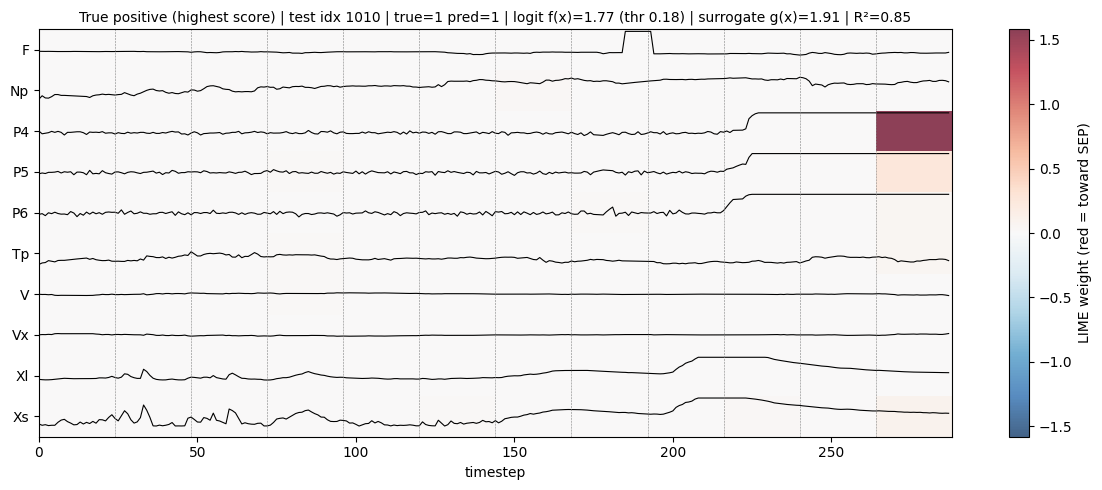

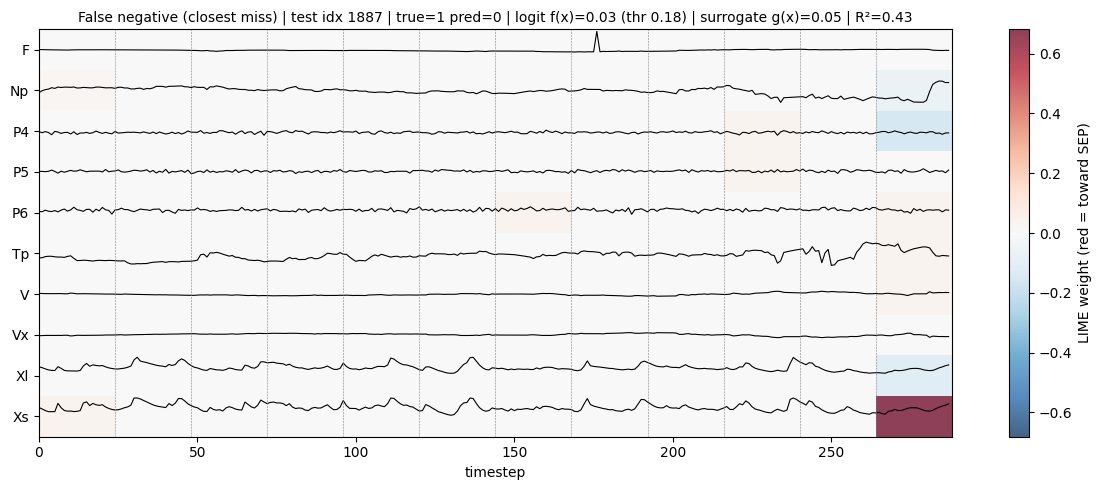

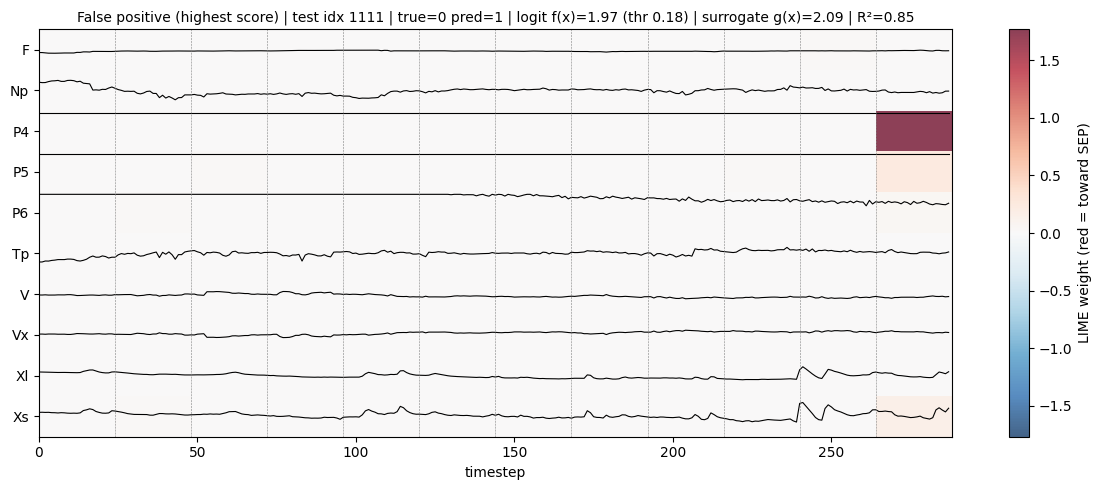

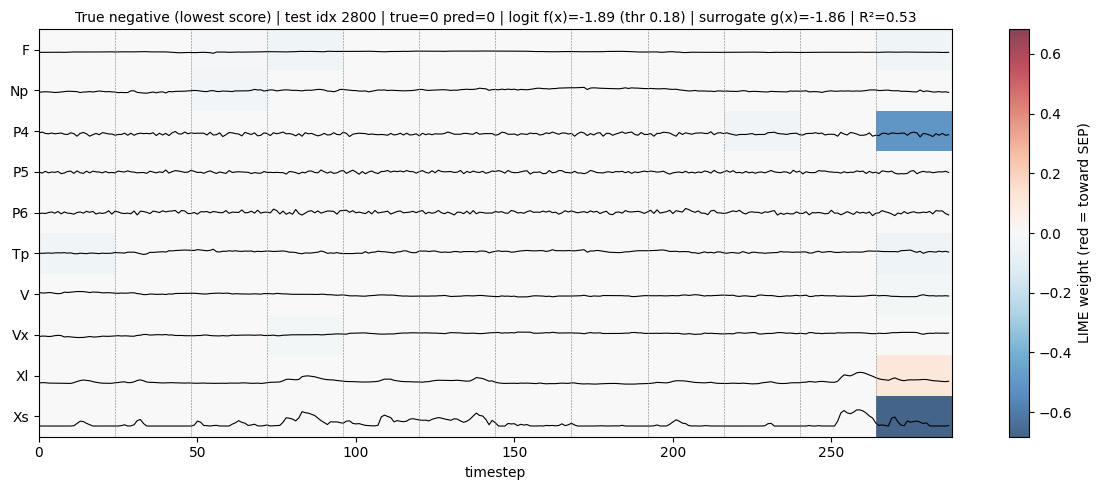

In [59]:
f_best = make_blackbox(art)
s_te, y_pred = art["s_te"], art["y_pred"]

def pick(mask, which):
    ii = np.flatnonzero(mask)
    if len(ii) == 0:
        return None
    return int(ii[np.argmax(s_te[ii])] if which == "high" else ii[np.argmin(s_te[ii])])

cases = {
    "True positive (highest score)":   pick((y_test == 1) & (y_pred == 1), "high"),
    "False negative (closest miss)":   pick((y_test == 1) & (y_pred == 0), "high"),
    "False positive (highest score)":  pick((y_test == 0) & (y_pred == 1), "high"),
    "True negative (lowest score)":    pick((y_test == 0) & (y_pred == 0), "low"),
}

for name, i in cases.items():
    if i is None:
        print(f"{name}: none in test set"); continue
    ex = lime_ts(f_best, X_test_norm[i], BACKGROUND, seed=i)
    title = (f"{name} | test idx {i} | true={y_test[i]} pred={y_pred[i]} | "
             f"logit f(x)={ex['f_x']:.2f} (thr {art['thr_logit']:.2f}) | surrogate g(x)={ex['g_x']:.2f} | R²={ex['r2']:.2f}")
    plot_explanation(X_test_norm[i], ex, title)

explaining 94 test windows
  explained 25/94
  explained 50/94
  explained 75/94
10s
surrogate weighted R²: mean 0.41 | median 0.37 | share < 0.5: 67%
  SEP: 24/34 explanations pass R² >= 0.5
  NSEP: 7/60 explanations pass R² >= 0.5


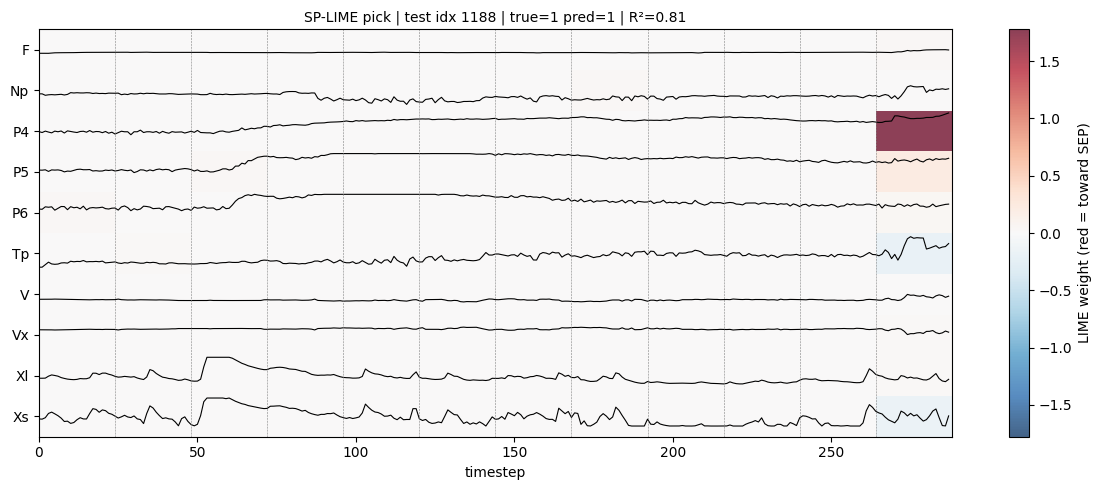

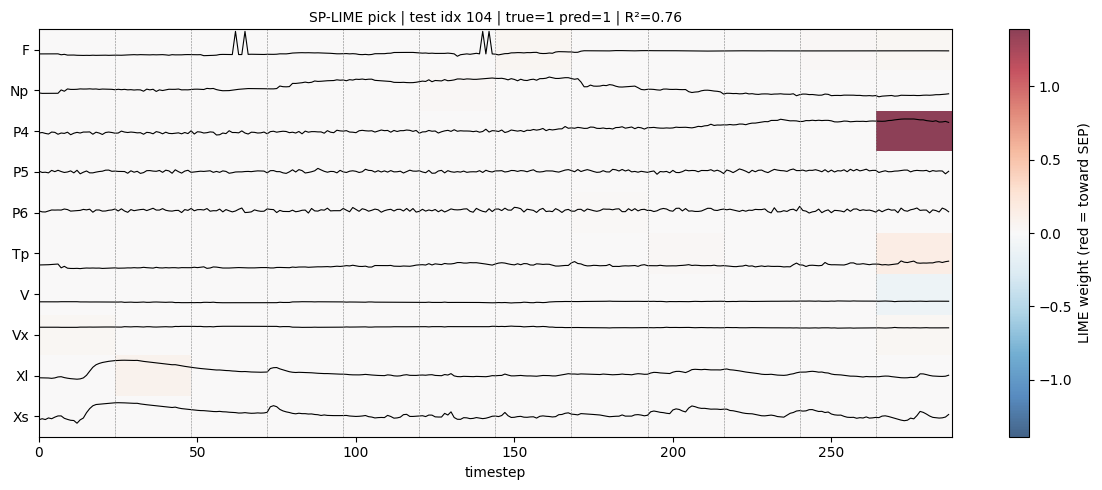

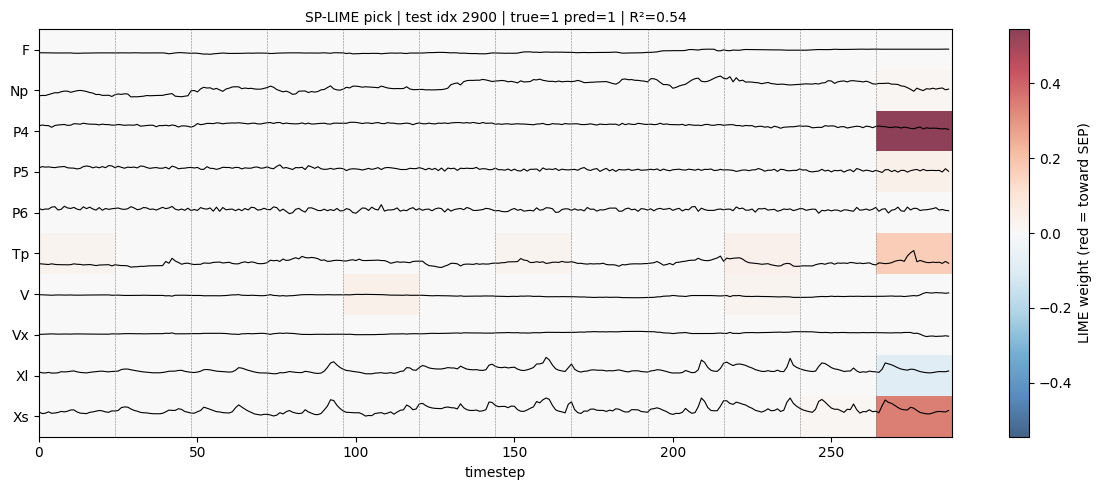

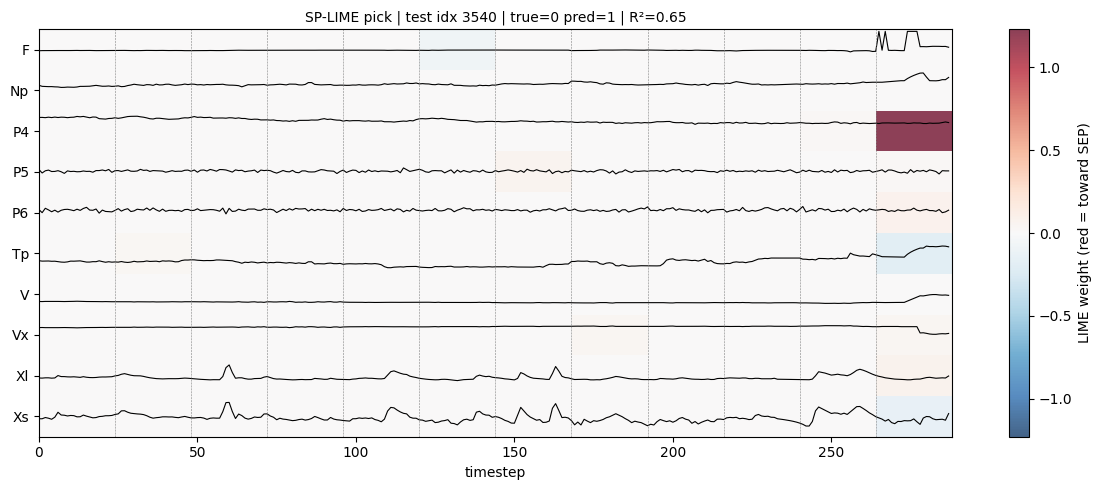

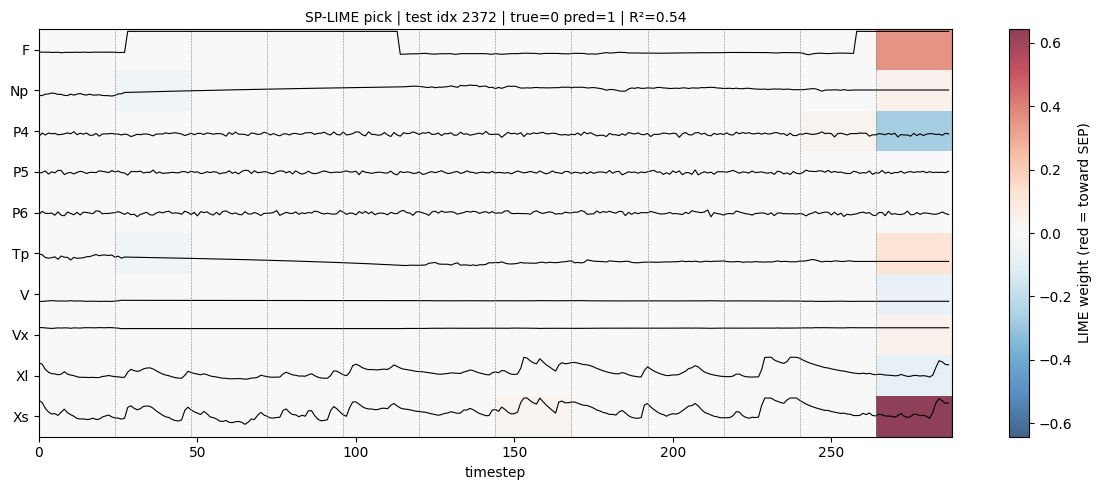

In [60]:
def explain_set(art, idxs, n_samples=2000, **kw):
    f = make_blackbox(art)
    out = []
    for n, i in enumerate(idxs):
        out.append(lime_ts(f, X_test_norm[i], BACKGROUND, n_samples=n_samples, seed=int(i), **kw))
        if (n + 1) % 25 == 0:
            print(f"  explained {n + 1}/{len(idxs)}", flush=True)
    return out

def submodular_pick(W_abs, B=5):
    I = np.sqrt(W_abs.sum(0))                                # global importance of each cell
    covered = np.zeros(W_abs.shape[1], bool)
    picked = []
    for _ in range(B):
        gains = ((W_abs > 0) & ~covered) @ I                 # marginal coverage gain
        gains[picked] = -1
        i = int(gains.argmax()); picked.append(i)
        covered |= W_abs[i] > 0
    return picked

R2_MIN = 0.5      # only trust explanations whose surrogate fits at least this well

def importance(expls, r2_min=None):
    # Aggregate |weights| over explanations; optionally keep only those with weighted R² >= r2_min
    r2 = np.array([e["r2"] for e in expls])
    keep = np.ones(len(expls), bool) if r2_min is None else (r2 >= r2_min)
    if keep.sum() == 0:
        raise ValueError(f"no explanation has R² >= {r2_min}; lower R2_MIN")
    W = np.stack([e["W"] for e, k in zip(expls, keep) if k])      # (n_kept, n_seg, C)
    A = np.abs(W)
    ch = A.sum(1).mean(0); seg = A.sum(2).mean(0)
    return dict(W=W, ch=ch / ch.sum(), seg=seg / seg.sum(), keep=keep)

N_PER_CLASS = 60
_rng = np.random.default_rng(LIME_SEED)
EXPL_IDX = np.concatenate([
    _rng.choice(np.flatnonzero(y_test == 1), min(N_PER_CLASS, int((y_test == 1).sum())), replace=False),
    _rng.choice(np.flatnonzero(y_test == 0), min(N_PER_CLASS, int((y_test == 0).sum())), replace=False),
])
print(f"explaining {len(EXPL_IDX)} test windows")

t0 = time.perf_counter()
expls = explain_set(art, EXPL_IDX)
print(f"{time.perf_counter() - t0:.0f}s")

r2 = np.array([e["r2"] for e in expls])
y_ex = y_test[EXPL_IDX]
print(f"surrogate weighted R²: mean {r2.mean():.2f} | median {np.median(r2):.2f} | share < {R2_MIN}: {(r2 < R2_MIN).mean():.0%}")
for cls, name in [(1, "SEP"), (0, "NSEP")]:
    print(f"  {name}: {int(((y_ex == cls) & (r2 >= R2_MIN)).sum())}/{int((y_ex == cls).sum())} explanations pass R² >= {R2_MIN}")

imp_all = importance(expls)               # every explanation (for comparison)
imp = importance(expls, R2_MIN)           # only reliable explanations (used by the cells below)

# SP-LIME on reliable explanations only, picked separately for SEP and NSEP windows
sp_picks = []
for cls, B in [(1, 3), (0, 2)]:
    cand = np.flatnonzero((y_ex == cls) & (r2 >= R2_MIN))
    if len(cand) == 0:
        print(f"no class-{cls} explanations pass the R² filter; lower R2_MIN to see some")
        continue
    W_abs = np.abs(np.stack([expls[p]["W"] for p in cand]).reshape(len(cand), -1))
    sp_picks += [int(cand[q]) for q in submodular_pick(W_abs, B=min(B, len(cand)))]

for p in sp_picks:
    i = EXPL_IDX[p]
    plot_explanation(X_test_norm[i], expls[p],
                     f"SP-LIME pick | test idx {i} | true={y_test[i]} pred={y_pred[i]} | R²={expls[p]['r2']:.2f}")

Text(0, 0.5, 'share')

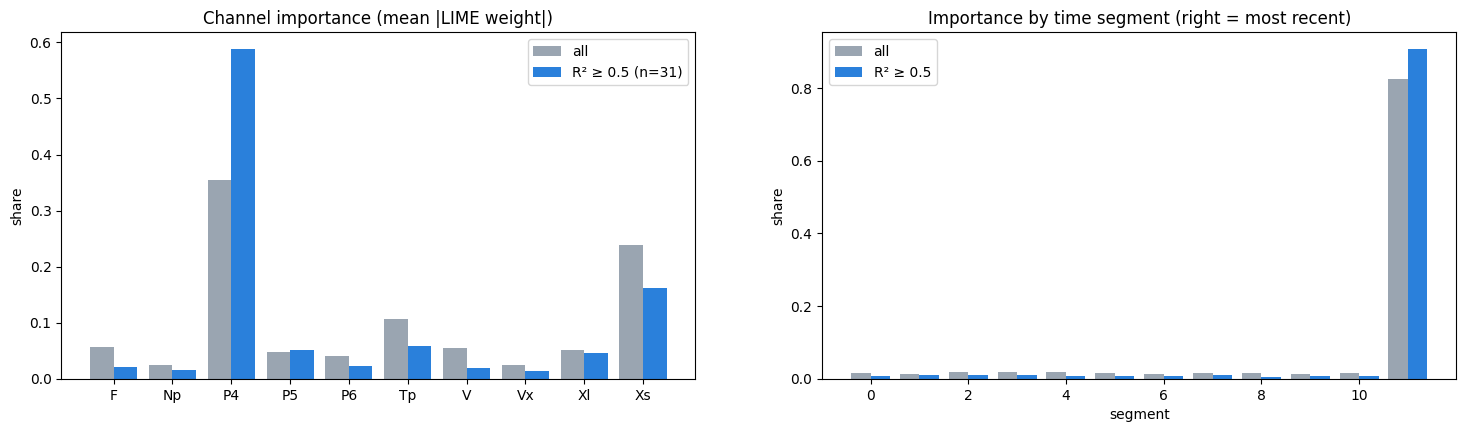

In [66]:
is_sep = (y_test[EXPL_IDX[imp["keep"]]] == 1)               # class of each kept (R² >= R2_MIN) explanation
n_keep = int(imp["keep"].sum())
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))

# Channel importance (mean |weight|, normalized): grey = all explanations, blue = only R² >= R2_MIN
xp = np.arange(len(CHANNEL_NAMES)); bw = 0.4
axes[0].bar(xp - bw / 2, imp_all["ch"], bw, color="#9aa5b1", label="all")
axes[0].bar(xp + bw / 2, imp["ch"], bw, color="#2a80db", label=f"R² ≥ {R2_MIN} (n={n_keep})")
axes[0].set_xticks(xp); axes[0].set_xticklabels(CHANNEL_NAMES); axes[0].legend()
axes[0].set_title("Channel importance (mean |LIME weight|)"); axes[0].set_ylabel("share")

# Time profile: importance by segment (oldest -> most recent)
sx = np.arange(len(imp["seg"]))
axes[1].bar(sx - bw / 2, imp_all["seg"], bw, color="#9aa5b1", label="all")
axes[1].bar(sx + bw / 2, imp["seg"], bw, color="#2a80db", label=f"R² ≥ {R2_MIN}")
axes[1].legend()
axes[1].set_title("Importance by time segment (right = most recent)")
axes[1].set_xlabel("segment"); axes[1].set_ylabel("share")


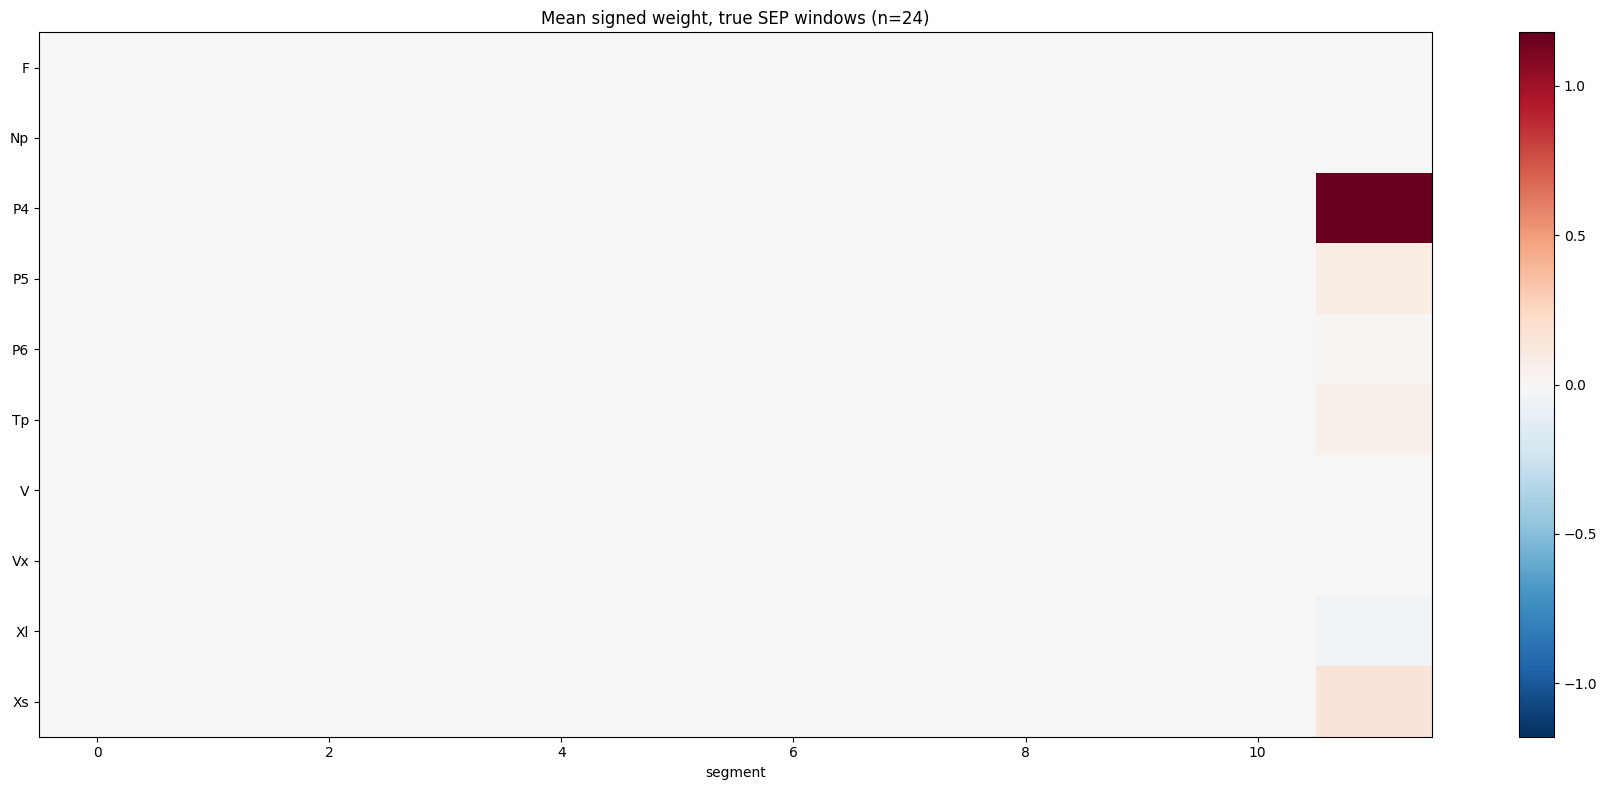

In [71]:
is_sep = (y_test[EXPL_IDX[imp["keep"]]] == 1)               # class of each kept (R² >= R2_MIN) explanation
n_keep = int(imp["keep"].sum())
fig, axes = plt.subplots(1, 1, figsize=(18, 8))

# Signed mean weight on true SEP windows: which (segment, channel) cells push toward SEP
S = imp["W"][is_sep].mean(0)
v = np.abs(S).max() + 1e-12
im = axes.imshow(S.T, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v)
axes.set_yticks(range(len(CHANNEL_NAMES))); axes.set_yticklabels(CHANNEL_NAMES)
axes.set_xlabel("segment"); axes.set_title(f"Mean signed weight, true SEP windows (n={int(is_sep.sum())})")
plt.colorbar(im, ax=axes)
plt.tight_layout(); plt.show()

In [62]:
ch_imp = pd.Series(imp["ch"], index=CHANNEL_NAMES, name="LIME importance")     # R² >= R2_MIN explanations
tbl = ch_imp.to_frame()
tbl["LIME importance (all windows)"] = imp_all["ch"]

if "df_ch" in globals():
    piv = df_ch.groupby("variant")["TSS"].mean()
    tbl["TSS drop when removed"] = [piv["all_channels"] - piv[f"drop_{c}"] if f"drop_{c}" in piv.index else np.nan
                                    for c in CHANNEL_NAMES]
    rho, p = stats.spearmanr(tbl["LIME importance"], tbl["TSS drop when removed"], nan_policy="omit")
    print(tbl.sort_values("LIME importance", ascending=False).round(3).to_string())
    print(f"\nSpearman(LIME importance, TSS drop) = {rho:.2f} (p={p:.3f}, n={tbl.dropna().shape[0]} channels)")
else:
    print(tbl.sort_values("LIME importance", ascending=False).round(3).to_string())
    print("\n(df_ch not found: run the Feature Selection cells to add the ablation comparison)")

    LIME importance  LIME importance (all windows)
P4            0.589                          0.354
Xs            0.162                          0.238
Tp            0.059                          0.106
P5            0.052                          0.048
Xl            0.045                          0.052
P6            0.023                          0.040
F             0.022                          0.057
V             0.019                          0.056
Np            0.015                          0.025
Vx            0.014                          0.024

(df_ch not found: run the Feature Selection cells to add the ablation comparison)
